# Лабораторна робота № 1

## Вхідний аналіз набору даних

**Дисципліна:** Інтелектуальний аналіз та візуалізація даних (СК26)
**Тривалість:** 2 год аудиторно + 3 год самостійної роботи · **Максимальна оцінка:** 4 бали

---

### Мета роботи

Пригадати роботу в Jupyter Notebook, бібліотеці `pandas` та побудову графіків —
і зробити це не на навчальному прикладі, а на реальному файлі, який ніхто не готував
спеціально для вас.

Ця робота виконується **до першої лекції**. Нічого нового знати не потрібно: усе,
що знадобиться, ви вже проходили в попередніх курсах. Усі поняття, яких ви тут
торкнетеся мимохідь, отримають назви й пояснення на лекціях 3 і 4.

### Дані

Файл `20171129_FINAL_FINAL.xlsx`, аркуш `Sheet1` — спостереження космічної погоди
за 28 серпня — 22 вересня 2017 року, зібрані з трьох різних джерел.

Файл видається **як є**, рівно в тому вигляді, у якому його колись вивантажили.
Ніхто не приводив його до ладу, і саме в цьому сенс: справжні дані здебільшого
надходять саме такими.

### Що ви маєте зробити

| Етап | Зміст | Де |
| --- | --- | --- |
| 1 | Розібратися, що взагалі лежить у файлі | аудиторно |
| 2 | Виділити три таблиці й привести їх до робочого вигляду | аудиторно |
| 3 | Скласти паспорт даних: що є, чого бракує, що виглядає дивно | аудиторно |
| 4 | Об'єднати три таблиці в одну | аудиторно |
| 5 | Побудувати п'ять графіків, кожен — відповідь на питання | аудиторно + самостійно |
| 6 | Порівняти два графіки одних і тих самих даних | самостійно |
| 7 | Записати три спостереження про дані | самостійно |
| 8 | Декларація про використання інструментів ШІ | самостійно |

### Що здається

1. Цей файл `.ipynb` із заповненими розв'язками. **Ноутбук має виконуватися згори
донизу на чистому ядрі** (Kernel → Restart & Run All) без помилок — це перевіряється
першою дією на захисті.
2. Файл `master_hourly.csv` — об'єднана таблиця з етапу 4.
3. Експорт ноутбука у HTML або PDF.
4. Заповнена декларація (етап 8). Без неї фінальна самоперевірка не проходить.

### Критерії оцінювання

| Бали | Що досягнуто |
| --- | --- |
| 0 | Дані не опрацьовано, графіки не побудовано або побудовано з грубими помилками |
| 1 | Таблиці прочитано й кілька графіків побудовано, але типи графіків не відповідають даним, дивних значень не помічено |
| 2 | Таблиці розібрано й об'єднано, графіки коректні та підписані, але висновків під ними немає або вони формальні |
| 4 | Усе вище виконано, знайдено й пояснено дивні значення, під кожним графіком є змістовний висновок про дані |

**Головне про оцінку:** бали ставляться не за наявність графіка, а за речення під ним.
Код, який нічого не пояснює, коштує двох балів з чотирьох.

---

## Нагадування про Jupyter

Якщо давно не працювали — три речі, які знадобляться сьогодні:

- `Shift+Enter` виконує клітинку, `Esc` `A` / `Esc` `B` додає клітинку вище / нижче,
`Esc` `M` перетворює клітинку на текстову (Markdown), `Esc` `Y` — назад на код.
- **Порядок виконання має значення.** Якщо ви правили клітинки в довільному порядку,
результат може залежати від історії запусків. Перед здачею обов'язково
**Kernel → Restart & Run All** — так ви побачите ноутбук очима викладача.
- Текстові клітинки — не прикраса. Висновки пишуться в них, а не в коментарях до коду.

---

## Крок 0. Ваші дані та варіант

Заповніть три змінні й виконайте обидві клітинки. Друга надрукує **ваше
індивідуальне завдання** — воно відрізняється від завдання сусіда.

In [1]:
ПІБ = 'Ільящук Марта Тарасівна'       
ГРУПА = 'ШІ-31'      
ВАРІАНТ = 7    

assert ПІБ and ГРУПА and ВАРІАНТ, 'Заповніть ПІБ, ГРУПУ та ВАРІАНТ'

In [2]:
# --- клітинку не редагувати: вона видає ваше персональне завдання ------------
ПОТОКИ = ['P>1', 'P>5', 'P>10', 'P>30', 'P>50', 'P>100', 'E>0.8', 'E>2.0']

ПАРИ = [('швидкість вітру', 'густина вітру'),
        ('швидкість вітру', 'потік P>10'),
        ('густина вітру', 'потік P>1'),
        ('радіопотік F10.7', 'потік P>10'),
        ('радіопотік F10.7', 'швидкість вітру'),
        ('потік E>0.8', 'потік P>10')]

АГРЕГАТИ = ['середнє', 'максимум', 'медіана', 'мінімум']

ПИТАННЯ = [
    'Скільки годин за все вікно ваш потік перевищував своє власне медіанне значення?',
    'У яку добу середнє значення вашого потоку було найбільшим? А найменшим?',
    'О котрій годині доби потік E>0.8 у середньому найбільший? Побудуйте графік середнього за годинами доби.',
    'Яка частка рядків об’єднаної таблиці має пропуск хоча б в одному стовпці?',
    'У який день радіопотік F10.7 був найбільшим і чи збігається цей день з піком вашого потоку?',
    'Порівняйте медіану вашого потоку за перший і за другий тиждень спостережень. У скільки разів вони відрізняються?',
    'Скільки годин поспіль тривала найдовша неперервна серія «активних» годин (група з етапу 4)?',
    'Який зі стовпців об’єднаної таблиці має найбільший розкид відносно власного середнього?',
    'Яку частку сумарного значення вашого потоку за все вікно дали 24 години навколо піку?',
    'Скільки різних діб потрапило у групу «активні» і скільки — у групу «дуже активні»?',
]

i = int(ВАРІАНТ)
завдання = {
    'ваш потік':                      ПОТОКИ[(i * 3 + 1) % 8],
    'ваша пара для графіка 3':        ' та '.join(ПАРИ[(i * 5 + 2) % 6]),
    'ваш агрегат для етапу 4':        АГРЕГАТИ[(i * 5 + 1) % 4],
    'ваше додаткове питання':         ПИТАННЯ[(i * 11 + 5) % 10],
}

print('ІНДИВІДУАЛЬНЕ ЗАВДАННЯ · %s, %s, варіант %d' % (ПІБ, ГРУПА, i))
print('=' * 78)
for k, v in завдання.items():
    print('%-28s %s' % (k + ':', v))

ІНДИВІДУАЛЬНЕ ЗАВДАННЯ · Ільящук Марта Тарасівна, ШІ-31, варіант 7
ваш потік:                   E>0.8
ваша пара для графіка 3:     швидкість вітру та потік P>10
ваш агрегат для етапу 4:     середнє
ваше додаткове питання:      О котрій годині доби потік E>0.8 у середньому найбільший? Побудуйте графік середнього за годинами доби.


Далі за текстом **«ваш потік»** означає стовпець, названий у першому рядку завдання.

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 40)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False,
                     'axes.spines.right': False, 'font.size': 9})

ФАЙЛ = '20171129_FINAL_FINAL.xlsx'

---

# Етап 1. Що взагалі лежить у файлі

Перше правило роботи з незнайомими даними: спершу подивитися, потім рахувати.

### Завдання 1.1

Спробуйте прочитати аркуш `Sheet1` звичайним способом — `pd.read_excel(ФАЙЛ)` —
і виведіть перші рядки та типи стовпців.

*Очікуваний результат: результат буде дивним. Подивіться на назви стовпців і на
те, які там типи даних. Поясніть у наступній клітинці, чому так вийшло.*

In [4]:
#%pip install openpyxl

In [5]:
# ВАШ КОД
df = pd.read_excel(ФАЙЛ)
print(df.head())
print(df.dtypes)

   Unnamed: 0        ftp://ftp.swpc.noaa.gov/pub/lists/particle/ Unnamed: 2 Unnamed: 3 Unnamed: 4 Unnamed: 5 Unnamed: 6 Unnamed: 7 Unnamed: 8 Unnamed: 9 Unnamed: 10 Unnamed: 11 Unnamed: 12  \
0         NaN                                                NaN        NaN        NaN        NaN        NaN        NaN        NaN        NaN        NaN         NaN         NaN         NaN   
1         NaN                :Data_list: 20170901_Gs_part_5m.txt        NaN        NaN        NaN        NaN        NaN        NaN        NaN        NaN         NaN         NaN         NaN   
2         NaN                     :Created: 2017 Sep 02 0011 UTC        NaN        NaN        NaN        NaN        NaN        NaN        NaN        NaN         NaN         NaN         NaN   
3         NaN  # Prepared by the U.S. Dept. of Commerce, NOAA...        NaN        NaN        NaN        NaN        NaN        NaN        NaN        NaN         NaN         NaN         NaN   
4         NaN  # Please send comments an

**Відповідь 1.1:** *(чому звичайне читання дало саме такий результат)*

Звичайне читання дало такий результат, оскільки:

1. pd.read_excel() за замовчуванням читає перший рядок аркуша як назви колонок, тому справжні назви потрапили у записи таблиць, а назвами колонок стали метадані та пусті значення таблиці(Unnamed: n), записані у першому рядку. NaN значення у таблиці з'явились через некоректне визначення меж таблиці та наявності порожніх клітинок.
2. Типи даних у таблиці - object через присутність даних різного типу у записах. Наприклад, у колонці Unnamed: 0 тип даних - float64 через наявність лише записів NaN.

### Завдання 1.2

Прочитайте аркуш ще раз, але **без заголовка**: `pd.read_excel(ФАЙЛ, header=None)`.
Виведіть його розмір і подивіться на перші 30 рядків.

In [6]:
# ВАШ КОД
RAW = pd.read_excel(ФАЙЛ, header=None)
print("Розмір датафрейму:", RAW.shape)
print(RAW.head(30))

Розмір датафрейму: (7226, 32)
    0                                                  1    2    3     4         5        6      7      8      9       10      11      12     13     14  15  \
0  NaN        ftp://ftp.swpc.noaa.gov/pub/lists/particle/  NaN  NaN   NaN       NaN      NaN    NaN    NaN    NaN     NaN     NaN     NaN    NaN    NaN NaN   
1  NaN                                                NaN  NaN  NaN   NaN       NaN      NaN    NaN    NaN    NaN     NaN     NaN     NaN    NaN    NaN NaN   
2  NaN                :Data_list: 20170901_Gs_part_5m.txt  NaN  NaN   NaN       NaN      NaN    NaN    NaN    NaN     NaN     NaN     NaN    NaN    NaN NaN   
3  NaN                     :Created: 2017 Sep 02 0011 UTC  NaN  NaN   NaN       NaN      NaN    NaN    NaN    NaN     NaN     NaN     NaN    NaN    NaN NaN   
4  NaN  # Prepared by the U.S. Dept. of Commerce, NOAA...  NaN  NaN   NaN       NaN      NaN    NaN    NaN    NaN     NaN     NaN     NaN    NaN    NaN NaN   
5  NaN  # Please

### Завдання 1.3

Для кожного стовпця порахуйте, скільки в ньому заповнених клітинок
(`RAW.notna().sum()`), і виведіть результат.

*Очікуваний результат: 32 числа. Серед них будуть нулі та згустки великих значень.
За цими згустками видно, що в аркуші **не одна таблиця, а кілька**, вставлені поруч.*

**Питання:** скільки таблиць в аркуші і які стовпці займає кожна?

In [7]:
# ВАШ КОД
print(RAW.notna().sum())

0        0
1     7223
2     7202
3     7202
4     7202
5     7203
6     7203
7     7198
8     7198
9     7198
10    7198
11    7198
12    7198
13    7198
14    7198
15       0
16      32
17      26
18      26
19      26
20       0
21       0
22       0
23       0
24     601
25     601
26     608
27     602
28     602
29     602
30     602
31     602
dtype: int64


**Відповідь 1.3:** *(скільки таблиць і які стовпці кожна займає)*

Три таблиці:

Перша таблиця: Unnamed: 0 - Unnamed: 14

Друга таблиця: Unnamed: 16 - Unnamed: 19

Третя таблиця: Unnamed: 24 - Unnamed: 31

### Завдання 1.4

Над кожною таблицею є кілька текстових рядків — це службовий опис від тих, хто дані
збирав. Виведіть їх і випишіть для кожної таблиці **джерело даних та одиниці
вимірювання**.

*Це найкорисніші п'ять хвилин роботи: жодної з цих відомостей у самій таблиці немає,
і без них ви не знатимете, у чому вимірюєте.*

In [8]:
# ВАШ КОД
print("Table_A")
print(RAW.iloc[0:22, 1].dropna().to_string(index=False))

print("\nTable_B")
print(RAW.iloc[0:23, 16].dropna().to_string(index=False))

print("\nTable_C")
print(RAW.iloc[0:7, 26].dropna().to_string(index=False))

Table_A
       ftp://ftp.swpc.noaa.gov/pub/lists/particle/
               :Data_list: 20170901_Gs_part_5m.txt
                    :Created: 2017 Sep 02 0011 UTC
# Prepared by the U.S. Dept. of Commerce, NOAA,...
# Please send comments and suggestions to SWPC....
                                                # 
              # Label: P > 1 = Particles at >1 Mev
              # Label: P > 5 = Particles at >5 Mev
             # Label: P >10 = Particles at >10 Mev
             # Label: P >30 = Particles at >30 Mev
             # Label: P >50 = Particles at >50 Mev
            # Label: P>100 = Particles at >100 Mev
            # Label: E>0.8 = Electrons at >0.8 Mev
            # Label: E>2.0 = Electrons at >2.0 Mev
            # Label: E>4.0 = Electrons at >4.0 Mev
             # Units: Particles = Protons/cm2-s-sr
           # Units: Electrons = Electrons/cm2-s-sr
                                 # Source: GOES-15
                                  # Location: W135
                       

**Відповідь 1.4:**

| Таблиця | Джерело | Одиниці вимірювання |
| --- | --- | --- |
| A | ftp://ftp.swpc.noaa.gov/pub/lists/particle/ | Protones/cm^2-s-sr
Electrons/cm^2-s-sr |
| B | ftp://ftp.swpc.noaa.gov/pub/indices/old_indices/2017Q3_DSD.txt | s.u.f. |
| C | [http://umtof.umd.edu/pm/crn/](http://umtof.umd.edu/pm/crn/) | Proton speed [km/sec]
Proton density [protons per cubic centimeter] |

---

# Етап 2. Три таблиці в робочому вигляді

У файлі три таблиці. Ось що в них лежить — решту ви вже знайшли самі:

| Таблиця | Стовпці аркуша | Що це | Один рядок = |
| --- | --- | --- | --- |
| A | B–O | вимірювання із супутника GOES-15: потоки частинок різної енергії | 5 хвилин |
| B | Q–T | добовий показник сонячної активності F10.7 | доба |
| C | Y–AF | швидкість і густина сонячного вітру | година |

### Завдання 2.1

Виділіть кожну таблицю в окремий `DataFrame` — назвіть їх `A`, `B` і `C`.
Дайте стовпцям осмислені назви й перетворіть значення на числа
(`pd.to_numeric(..., errors='coerce')` стане в пригоді).

In [9]:
# ВАШ КОД
A = RAW.iloc[25:, 1:15].copy()
A.columns = [
    "YR",
    "MO",
    "DA",
    "HHMM",
    "Modified_Julian_Day",
    "Seconds_of_Day",
    "P>1",
    "P>5",
    "P>10",
    "P>30",
    "P>50",
    "P>100",
    "E>0.8",
    "E>2.0",
]
A = A.apply(pd.to_numeric, errors="coerce").dropna(how="all").reset_index(drop=True)

print(A.head())

B = RAW.iloc[26:, 16:20].copy()
B.columns = ["YR", "MO", "DA", "Radio_Flux_10.7"]
B = B.apply(pd.to_numeric, errors="coerce").dropna(how="all").reset_index(drop=True)

print(B.head())

C = C = RAW.iloc[26:, 26:32].copy()
C.columns = ["YR", "MO", "DA", "HH", "SPEED", "DENSITY"]
C = C.apply(pd.to_numeric, errors="coerce").dropna(how="all").reset_index(drop=True)

print(C.head())

       YR   MO    DA  HHMM  Modified_Julian_Day  Seconds_of_Day    P>1    P>5   P>10    P>30    P>50   P>100    E>0.8   E>2.0
0  2017.0  8.0  28.0   0.0              57993.0             0.0  12.00  0.260  0.180  0.1140  0.1040  0.0793  23600.0  1180.0
1  2017.0  8.0  28.0   5.0              57993.0           300.0  19.40  0.690  0.314  0.1120  0.0612  0.0251  23100.0  1160.0
2  2017.0  8.0  28.0  10.0              57993.0           600.0   8.48  0.168  0.130  0.0717  0.0614  0.0304  22200.0  1090.0
3  2017.0  8.0  28.0  15.0              57993.0           900.0  15.40  0.566  0.198  0.0926  0.0568  0.0251  20400.0   997.0
4  2017.0  8.0  28.0  20.0              57993.0          1200.0   6.41  0.156  0.118  0.0597  0.0494  0.0251  18500.0   875.0
       YR   MO    DA  Radio_Flux_10.7
0  2017.0  8.0  28.0             82.0
1  2017.0  8.0  29.0             84.0
2  2017.0  8.0  30.0             87.0
3  2017.0  8.0  31.0             92.0
4  2017.0  9.0   1.0             93.0
     YR   MO    

### Завдання 2.2

У кожній таблиці дата й час записані **по-різному** й розкидані по кількох стовпцях.
Зберіть для кожної таблиці один стовпець `ts` типу `datetime`.

Після цього обов'язково виведіть для кожної таблиці найранішу й найпізнішу дату.

*Очікуваний результат: усі три таблиці мають лежати в межах серпня–вересня 2017 року.
Якщо у вас вийшов інший рік — придивіться, як записано рік у тій таблиці, і виправте.*

In [10]:
# ВАШ КОД
for df in [A, B, C]:
    df["YR"] = df["YR"].astype(int).apply(lambda y: y + 2000 if y < 100 else y)

hhmm_str = A["HHMM"].astype(int).astype(str).str.zfill(4)

date_str_A = (
    A["YR"].astype(int).astype(str)
    + "-"
    + A["MO"].astype(int).astype(str)
    + "-"
    + A["DA"].astype(int).astype(str)
    + " "
    + hhmm_str
)
A["ts"] = pd.to_datetime(date_str_A, format="%Y-%m-%d %H%M")


B["ts"] = pd.to_datetime(
    B[["YR", "MO", "DA"]]
    .astype(int)
    .rename(columns={"YR": "year", "MO": "month", "DA": "day"})
)


C["ts"] = pd.to_datetime(
    C[["YR", "MO", "DA", "HH"]]
    .astype(int)
    .rename(columns={"YR": "year", "MO": "month", "DA": "day", "HH": "hour"})
)


print(f"Table_A min = {A['ts'].min()}, max = {A['ts'].max()}")
print(f"Table_B min = {B['ts'].min()}, max = {B['ts'].max()}")
print(f"Table_C min ={C['ts'].min()}, max = {C['ts'].max()}")

Table_A min = 2017-08-28 00:00:00, max = 2017-09-21 23:55:00
Table_B min = 2017-08-28 00:00:00, max = 2017-09-21 00:00:00
Table_C min =2017-08-28 00:00:00, max = 2017-09-22 00:00:00


**Самоперевірка етапу 2.** Клітинка має виконатися без помилок.

In [11]:
assert len(A) == 7200, 'у таблиці A має бути 7200 рядків, а є %d' % len(A)
assert len(B) == 25,   'у таблиці B має бути 25 рядків, а є %d' % len(B)
assert len(C) == 601,  'у таблиці C має бути 601 рядок, а є %d' % len(C)
for назва, т in [('A', A), ('B', B), ('C', C)]:
    рік = pd.to_datetime(т['ts']).dt.year
    assert рік.min() == 2017 and рік.max() == 2017, 'у таблиці %s рік не 2017 — перевірте збирання дати' % назва
print('Етап 2 пройдено')

Етап 2 пройдено


---

# Етап 3. Паспорт даних

### Завдання 3.1

Для кожної таблиці виведіть: розмір, типи стовпців, кількість пропусків у кожному
стовпці, кількість повних дублікатів рядків і описові статистики (`describe()`).

In [12]:
# ВАШ КОД
tables = {
    "Table_A": A,
    "Table_B": B,
    "Table_C": C,
}

for name, df in tables.items():
    print(name)
    print(f"1. Розмірність (рядків, стовпчиків): {df.shape}")

    print("\n2-3. Типи стовпців та кількість пропусків:")
    passport_df = pd.DataFrame(
        {
            "Тип даних": df.dtypes,
            "Кількість пропусків": df.isna().sum(),
            "% пропусків": (df.isna().mean() * 100).round(2),
        }
    )
    display(passport_df)

    duplicates_count = df.duplicated().sum()
    print(f"\n4. Кількість повних дублікатів рядків: {duplicates_count}")

    print("\n5. Описові статистики (describe):")
    display(df.describe())
    print("\n\n")

Table_A
1. Розмірність (рядків, стовпчиків): (7200, 15)

2-3. Типи стовпців та кількість пропусків:


,Тип даних,Кількість пропусків,% пропусків
YR,int64,0,0.00
MO,float64,0,0.00
DA,float64,0,0.00
HHMM,float64,0,0.00
Modified_Julian_Day,float64,0,0.00
Seconds_of_Day,float64,0,0.00
P>1,float64,3,0.04
P>5,float64,3,0.04
P>10,float64,3,0.04
P>30,float64,3,0.04



4. Кількість повних дублікатів рядків: 0

5. Описові статистики (describe):


,YR,MO,DA,HHMM,Modified_Julian_Day,Seconds_of_Day,P>1,P>5,P>10,P>30,P>50,P>100,E>0.8,E>2.0,ts
count,7200.0,7200.000000,7200.000000,7200.000000,7200.000000,7200.000000,7197.000000,7197.000000,7197.000000,7197.000000,7197.000000,7197.00000,7197.000000,7197.000000,7200
mean,2017.0,8.840000,13.960000,1177.500000,58005.000000,43050.000000,689.325064,156.626057,76.474020,18.838604,7.446840,1.65929,81862.741801,11401.502123,2017-09-09 11:57:30
min,2017.0,8.000000,1.000000,0.000000,57993.000000,0.000000,0.429000,0.151000,0.117000,0.057600,0.045500,0.02240,4.300000,0.133000,2017-08-28 00:00:00
25%,2017.0,9.000000,7.000000,588.750000,57999.000000,21525.000000,11.700000,0.279000,0.186000,0.098400,0.059700,0.02630,22200.000000,552.000000,2017-09-03 05:58:45
50%,2017.0,9.000000,13.000000,1177.500000,58005.000000,43050.000000,55.400000,0.632000,0.376000,0.146000,0.086600,0.03630,68600.000000,4290.000000,2017-09-09 11:57:30
75%,2017.0,9.000000,19.000000,1766.250000,58011.000000,64575.000000,560.000000,107.000000,35.800000,0.990000,0.249000,0.06700,143000.000000,14100.000000,2017-09-15 17:56:15
max,2017.0,9.000000,31.000000,2355.000000,58017.000000,86100.000000,32500.000000,2890.000000,1330.000000,399.000000,191.000000,61.50000,259000.000000,110000.000000,2017-09-21 23:55:00
std,0.0,0.366632,8.775483,692.481902,7.211603,24943.113498,1625.968447,390.921861,222.362627,67.265595,28.620524,7.15889,65728.005824,16920.617446,NaN





Table_B
1. Розмірність (рядків, стовпчиків): (25, 5)

2-3. Типи стовпців та кількість пропусків:


...

,YR,MO,DA,Radio_Flux_10.7,ts
count,25.0,25.000000,25.000000,25.000000,25
mean,2017.0,8.840000,13.960000,92.680000,2017-09-09 00:00:00
min,2017.0,8.000000,1.000000,71.000000,2017-08-28 00:00:00
25%,2017.0,9.000000,7.000000,74.000000,2017-09-03 00:00:00
50%,2017.0,9.000000,13.000000,84.000000,2017-09-09 00:00:00
75%,2017.0,9.000000,19.000000,107.000000,2017-09-15 00:00:00
max,2017.0,9.000000,31.000000,140.000000,2017-09-21 00:00:00
std,0.0,0.374166,8.955817,22.206831,NaN





Table_C
1. Розмірність (рядків, стовпчиків): (601, 7)

2-3. Типи стовпців та кількість пропусків:


,Тип даних,Кількість пропусків,% пропусків
YR,int64,0,0.0
MO,float64,0,0.0
DA,float64,0,0.0
HH,float64,0,0.0
SPEED,float64,0,0.0
DENSITY,float64,0,0.0
ts,datetime64[ns],0,0.0



4. Кількість повних дублікатів рядків: 0

5. Описові статистики (describe):


,YR,MO,DA,HH,SPEED,DENSITY,ts
count,601.0,601.000000,601.000000,601.000000,601.000000,601.000000,601
mean,2017.0,8.840266,13.973378,11.480865,506.547421,2.907654,2017-09-09 12:00:00
min,2017.0,8.000000,1.000000,0.000000,-1.000000,-1.000000,2017-08-28 00:00:00
25%,2017.0,9.000000,7.000000,5.000000,447.000000,1.800000,2017-09-03 06:00:00
50%,2017.0,9.000000,13.000000,11.000000,517.000000,2.400000,2017-09-09 12:00:00
75%,2017.0,9.000000,19.000000,17.000000,584.000000,3.400000,2017-09-15 18:00:00
max,2017.0,9.000000,31.000000,23.000000,806.000000,31.700000,2017-09-22 00:00:00
std,0.0,0.366664,8.781000,6.938063,125.073291,2.637873,NaN


### Завдання 3.2 — дивні значення

Подивіться на рядок `min` у таблиці `describe()` для таблиці C.

Швидкість і густина — фізичні величини, які **не можуть бути від'ємними**.
Знайдіть від'ємні значення, порахуйте, скільки їх, і поверніться до службового опису
з завдання 1.4: там написано, що вони означають.

Замініть ці значення на `NaN` і покажіть, як після цього змінилися середнє й мінімум.

*Очікуваний результат: два числа «до» і «після» для кожного зі стовпців.*

In [13]:
# ВАШ КОД

speed_min_1 = C["SPEED"].min()
speed_mean_1 = C["SPEED"].mean()
density_min_1 = C["DENSITY"].min()
density_mean_1 = C["DENSITY"].mean()

speed_neg_count = (C["SPEED"] < 0).sum()
density_neg_count = (C["DENSITY"] < 0).sum()

print(
    f"Знайдено від'ємних значень у SPEED: {speed_neg_count}"
)
print(
    f"Знайдено від'ємних значень у DENSITY: {density_neg_count}\n"
)

C.loc[C["SPEED"] < 0, "SPEED"] = np.nan
C.loc[C["DENSITY"] < 0, "DENSITY"] = np.nan

speed_min_2 = C["SPEED"].min()
speed_mean_2 = C["SPEED"].mean()
density_min_2 = C["DENSITY"].min()
density_mean_2 = C["DENSITY"].mean()

results_df = pd.DataFrame(
    {
        "SPEED: min": [speed_min_1, speed_min_2],
        "SPEED: mean": [speed_mean_1, speed_mean_2],
        "DENSITY: min": [density_min_1, density_min_2],
        "DENSITY: mean": [density_mean_1, density_mean_2],
    },
    index=["До", "Після"],
)

display(results_df.round(2))

Знайдено від'ємних значень у SPEED: 8
Знайдено від'ємних значень у DENSITY: 8



,SPEED: min,SPEED: mean,DENSITY: min,DENSITY: mean
До,-1.0,506.55,-1.0,2.91
Після,277.0,513.39,0.1,2.96


**Відповідь 3.2:** *(що це за значення, скільки їх, як вони спотворювали середнє)*
Позначення -999.0 (або -999, -9999) у наукових даних — це службовий прапорець відсутності вимірювань.
Додавання до суми відємних значень зменшує чисельник, через що підсумкове середнє занижується.

### Завдання 3.3 — питання на подумати

У таблиці A є стовпці, для яких `describe()` слухняно рахує середнє й стандартне
відхилення, хоча ці числа не мають жодного сенсу.

Знайдіть їх і поясніть своїми словами, чому середнє для них безглузде.

*Підказка: не кожне число в таблиці є результатом вимірювання.*

> Це питання не має однієї «правильної» відповіді з підручника — на нього ви
> відповідаєте з власного здорового глузду. Формальне пояснення буде на лекції 3.

In [14]:
# ВАШ КОД
non_measurement_cols = [
    "YR",
    "MO",
    "DA",
    "HHMM",
    "Modified_Julian_Day",
    "Seconds_of_Day",
]
display(A[non_measurement_cols].describe().round(2))

,YR,MO,DA,HHMM,Modified_Julian_Day,Seconds_of_Day
count,7200.0,7200.00,7200.00,7200.00,7200.00,7200.00
mean,2017.0,8.84,13.96,1177.50,58005.00,43050.00
std,0.0,0.37,8.78,692.48,7.21,24943.11
min,2017.0,8.00,1.00,0.00,57993.00,0.00
25%,2017.0,9.00,7.00,588.75,57999.00,21525.00
50%,2017.0,9.00,13.00,1177.50,58005.00,43050.00
75%,2017.0,9.00,19.00,1766.25,58011.00,64575.00
max,2017.0,9.00,31.00,2355.00,58017.00,86100.00


**Відповідь 3.3:** *(які це стовпці та чому середнє для них не має сенсу)*
Це стовпці які позначають дату чи час.
Середнє значення для цих колонок не несе змісту і не має практичного застосування, бо утворюються дані які не можуть фізично існувати(наприклад місяць 8.84).

---

# Етап 4. Об'єднання трьох таблиць в одну

Таблиці мають різний крок у часі: 5 хвилин, година і доба. Щоб працювати з ними
разом, потрібна спільна сітка. Беремо **годину**.

Кожна таблиця потребує своєї дії:

1. **A: 5 хвилин → година.** Кілька рядків згортаються в один — це `resample` + агрегація.
2. **C: уже година.** Просте з'єднання по спільному стовпцю `ts` — `merge`.
3. **B: доба → година.** Навпаки, одне значення розтягується на 24 години доби.

### Завдання 4.1

Зведіть таблицю A до погодинної сітки. Для кожного потоку порахуйте **два** числа
за годину: середнє і максимум.

In [15]:
# ВАШ КОД
flux_cols = ["P>1", "P>5", "P>10", "P>30", "P>50", "P>100", "E>0.8", "E>2.0"]

A_hourly = A.set_index("ts")[flux_cols].resample("1h").agg(["mean", "max"])

A_hourly = A_hourly.reset_index()

print(
    f"Кількість рядків до {len(A)}, після (погодинно): {len(A_hourly)}"
)
display(A_hourly.head())

Кількість рядків до 7200, після (погодинно): 600


ts       P>1              P>5             P>10             P>30              P>50             P>100                 E>0.8                 E>2.0        
                           mean    max      mean    max      mean    max      mean     max      mean     max      mean     max          mean      max         mean     max
0 2017-08-28 00:00:00  9.778333  19.40  0.324917  0.690  0.192917  0.314  0.098850  0.2240  0.077583  0.1780  0.040692  0.0793  20941.666667  23600.0  1011.583333  1180.0
1 2017-08-28 01:00:00  7.994167  13.60  0.291667  0.512  0.156583  0.259  0.072583  0.0919  0.058700  0.0798  0.029950  0.0471  18091.666667  20600.0   713.000000   907.0
2 2017-08-28 02:00:00  6.099167  10.80  0.283000  0.479  0.177667  0.321  0.084450  0.1210  0.069642  0.1110  0.035025  0.0595  14108.333333  15000.0   380.833333   475.0
3 2017-08-28 03:00:00  4.752500   7.76  0.236833  0.329  0.166333  0.244  0.087658  0.1800  0.068092  0.1390  0.035517  0.0818  12766.666667  13100.0   267.916667   284.0
4 2017-08-28 04:00:00  4.158333   6.62  0.334917  0.539  0.208333  0.309  0.084800  0.1530  0.072850  0.1420  0.039708  0.0694  11333.333333  12300.0   203.000000   234.0

### Завдання 4.2

У вашому завданні названо агрегат (`середнє`, `максимум`, `медіана` або `мінімум`).

Візьміть ваш потік за одну добу, порахуйте для нього по годинах ваш агрегат і ще один
на ваш вибір, і побудуйте обидві криві на одному графіку.

**Питання:** чим вони відрізняються і в якій ситуації різниця між ними стане суттєвою?

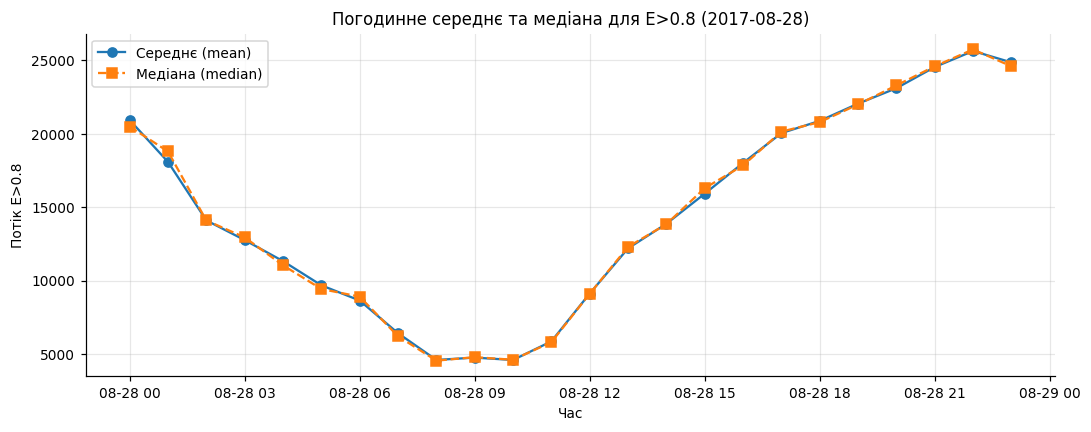

In [ ]:
# ВАШ КОД

one_day = A[A["ts"].dt.date == pd.to_datetime("2017-08-28").date()]

day_hourly = (
    one_day.set_index("ts")["E>0.8"]
    .resample("1h")
    .agg(["mean", "median"])
    .reset_index()
)

plt.figure(figsize=(10, 4))
plt.plot(
    day_hourly["ts"],
    day_hourly["mean"],
    label="Середнє (mean)",
    marker="o",
)
plt.plot(
    day_hourly["ts"],
    day_hourly["median"],
    label="Медіана (median)",
    marker="s",
    linestyle="--",
)

plt.title("Погодинне середнє та медіана для E>0.8 (2017-08-28)")
plt.xlabel("Час")
plt.ylabel("Потік E>0.8")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

**Відповідь 4.2:** *(чим відрізняються криві та коли це важливо)*
Кол потік стабільний криві збігаються, але при коливаннях потоку
Якщо mean > median — у цій годині були поодинокі (піки).
Якщо median > mean — у цій годині були поодинокі (просідання).

### Завдання 4.3

Об'єднайте три таблиці в одну — назвіть її `M`. Виведіть її розмір і всі рядки,
у яких є хоча б один пропуск.

**Зверніть увагу:** таблиці закінчуються не в один і той самий момент. Тому результат
залежить від того, який тип об'єднання ви оберете (`how='inner'` чи `how='outer'`).
Спробуйте обидва, подивіться, чим відрізняється кількість рядків, і поясніть свій вибір.

In [17]:
# ВАШ КОД

B_hourly = B.set_index("ts").resample("1h").ffill().reset_index()

if isinstance(A_hourly.columns, pd.MultiIndex):
    A_hourly.columns = [
        f"{c[0]}_{c[1]}".strip("_") if c[1] else c[0]
        for c in A_hourly.columns
    ]

#  Варіант 1: INNER JOIN
M_inner = A_hourly.merge(C, on="ts", how="inner").merge(
    B_hourly, on="ts", how="inner"
)

# Варіант 2: OUTER JOIN
M_outer = A_hourly.merge(C, on="ts", how="outer").merge(
    B_hourly, on="ts", how="outer"
)


print(f"Розмір M (inner): {M_inner.shape}")
print(f"Розмір M (outer): {M_outer.shape}\n")

M = M_outer
nan_rows = M[M.isna().any(axis=1)]

print(f"Кількість рядків з хоча б одним пропуском: {len(nan_rows)}")
display(nan_rows)

Розмір M (inner): (577, 27)
Розмір M (outer): (601, 27)

Кількість рядків з хоча б одним пропуском: 32


,ts,P>1_mean,P>1_max,P>5_mean,P>5_max,P>10_mean,P>10_max,P>30_mean,P>30_max,P>50_mean,P>50_max,P>100_mean,P>100_max,E>0.8_mean,E>0.8_max,E>2.0_mean,E>2.0_max,YR_x,MO_x,DA_x,HH,SPEED,DENSITY,YR_y,MO_y,DA_y,Radio_Flux_10.7
175,2017-09-04 07:00:00,6.465833,10.10,0.262083,0.593,0.171500,0.294,0.085483,0.145,0.068558,0.1340,0.031717,0.0523,90600.000000,100000.0,7410.833333,8950.0,2017,9.0,4.0,7.0,NaN,NaN,2017.0,9.0,4.0,140.0
176,2017-09-04 08:00:00,4.010833,5.08,0.256000,0.432,0.195833,0.336,0.086625,0.145,0.070033,0.1340,0.036492,0.0546,73483.333333,79300.0,5048.333333,5850.0,2017,9.0,4.0,8.0,NaN,NaN,2017.0,9.0,4.0,140.0
177,2017-09-04 09:00:00,3.268333,4.42,0.303417,0.518,0.220333,0.302,0.105925,0.162,0.081975,0.1340,0.046483,0.0765,60475.000000,68500.0,3715.833333,4480.0,2017,9.0,4.0,9.0,NaN,NaN,2017.0,9.0,4.0,140.0
178,2017-09-04 10:00:00,3.179167,4.74,0.252167,0.372,0.181833,0.280,0.101900,0.150,0.081675,0.1200,0.054125,0.0894,64383.333333,68400.0,4122.500000,4710.0,2017,9.0,4.0,10.0,NaN,NaN,2017.0,9.0,4.0,140.0
179,2017-09-04 11:00:00,5.274167,7.98,0.295083,0.657,0.186917,0.276,0.089525,0.166,0.063983,0.1100,0.033633,0.0684,79933.333333,88200.0,6345.833333,7430.0,2017,9.0,4.0,11.0,NaN,NaN,2017.0,9.0,4.0,140.0
180,2017-09-04 12:00:00,2.965000,4.85,0.217750,0.428,0.153500,0.239,0.089217,0.179,0.071217,0.1440,0.037233,0.0679,80516.666667,88700.0,6080.000000,7420.0,2017,9.0,4.0,12.0,NaN,NaN,2017.0,9.0,4.0,140.0
181,2017-09-04 13:00:00,3.061667,3.86,0.275833,0.551,0.192833,0.329,0.104542,0.170,0.083783,0.1590,0.041342,0.0611,76733.333333,85900.0,6015.833333,7540.0,2017,9.0,4.0,13.0,NaN,NaN,2017.0,9.0,4.0,140.0
182,2017-09-04 14:00:00,7.279167,10.80,0.231333,0.409,0.170583,0.313,0.086508,0.178,0.070667,0.1660,0.037375,0.0888,83025.000000,90200.0,8552.500000,10500.0,2017,9.0,4.0,14.0,NaN,NaN,2017.0,9.0,4.0,140.0
577,2017-09-21 01:00:00,37.408333,56.30,0.268250,0.375,0.196667,0.335,0.116075,0.255,0.078192,0.1600,0.039483,0.0737,159833.333333,164000.0,38200.000000,41400.0,2017,9.0,21.0,1.0,453.0,1.9,NaN,NaN,NaN,NaN
578,2017-09-21 02:00:00,36.841667,48.60,0.357250,0.774,0.229333,0.493,0.100842,0.154,0.071567,0.1290,0.038883,0.0737,150583.333333,158000.0,32333.333333,36000.0,2017,9.0,21.0,2.0,453.0,1.9,NaN,NaN,NaN,NaN


**Відповідь 4.3:** *(який тип об'єднання обрано, скільки рядків дає кожен і чому)*
Обрано how ='inner', оскільки при how ='outer' отримаємо усі значення з'єднаних таблиць навіть ті що не мають спільних рядків (тобто NaN значення), що ускладнює статистичні обчислення.

### Завдання 4.4 — поділ на групи

Щоб далі було що з чим порівнювати, поділіть години на три групи за значенням
**максимуму потоку P>10 за годину**:

| Група | Умова |
| --- | --- |
| `тиха` | менше 10 |
| `активна` | від 10 до 1000 |
| `дуже активна` | 1000 і більше |

Додайте до `M` стовпець `група` і виведіть, скільки годин потрапило в кожну.

> Це не вигадані числа: саме такі пороги використовує метеослужба космічної погоди
> NOAA. Чому вони саме такі — питання не сьогоднішньої роботи.

In [18]:
# ВАШ КОД

bins = [-np.inf, 10, 1000, np.inf]
labels = ["тиха", "активна", "дуже активна"]


target_col = "P>10_max" 

M["група"] = pd.cut(M[target_col], bins=bins, labels=labels, right=False)

print(M["група"].value_counts())

група
тиха            411
активна         171
дуже активна     18
Name: count, dtype: int64


**Самоперевірка етапу 4.**

In [19]:
assert M is not None, 'таблиця M не побудована'
assert 'ts' in M.columns, 'у таблиці M потрібен стовпець ts'
assert 'група' in M.columns, 'у таблиці M потрібен стовпець «група»'
assert 590 <= len(M) <= 605, 'очікується близько 600 рядків, а є %d — перевірте об’єднання' % len(M)
print('Етап 4 пройдено:', len(M), 'рядків')

Етап 4 пройдено: 601 рядків


---

# Етап 5. П'ять графіків — п'ять питань

Графік будується як **відповідь на питання**, а не «щоб був».

**Вимоги до кожного графіка:**

- підписані обидві осі, з одиницями вимірювання;
- заголовок;
- під графіком, у текстовій клітинці, — **одне речення про дані**.
Не «на графіку зображено потік протонів», а твердження на кшталт
«більшість годин потік не перевищує 60, але кілька годин дають значення у сотні разів більші».

> Не кожне питання має відповідь «так, зв'язок є». Якщо на графіку нічого не видно —
> так і напишіть. Відсутність зв'язку — це теж результат, і чесно про неї написати
> важливіше, ніж підбирати ракурс, у якому «щось наче проглядається».

### Графік 1. Як розподілені значення вашого потоку?

Побудуйте гістограму вашого потоку (середнє за годину). Порахуйте окремо середнє
й медіану цього стовпця.

Якщо гістограма вийде нечитабельною — стовпчик біля нуля і порожньо далі — не
залишайте так. Спробуйте побудувати гістограму від логарифма значень
(`np.log10`) і подивіться, що зміниться.

**Питання:** чому середнє й медіана так сильно відрізняються?

Середнє арифметичне потоку E>0.8: 81842.47
Медіана потоку E>0.8:             69712.50



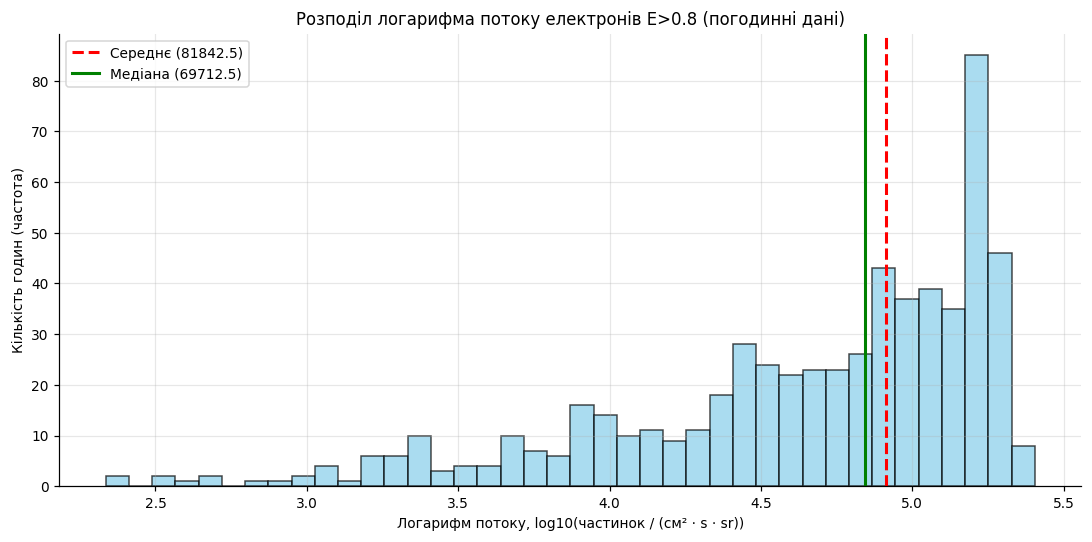

In [ ]:
# ВАШ КОД
flux_col = "E>0.8_mean" 

flux_mean = M[flux_col].mean()
flux_median = M[flux_col].median()

print(f"Середнє арифметичне потоку E>0.8: {flux_mean:.2f}")
print(f"Медіана потоку E>0.8:             {flux_median:.2f}\n")

log_flux = np.log10(M[M[flux_col] > 0][flux_col])

plt.figure(figsize=(10, 5))
plt.hist(log_flux, bins=40, color="skyblue", edgecolor="black", alpha=0.7)

plt.axvline(
    x=np.log10(flux_mean),
    color="red",
    linestyle="--",
    linewidth=2,
    label=f"Середнє ({flux_mean:.1f})",
)
plt.axvline(
    x=np.log10(flux_median),
    color="green",
    linestyle="-",
    linewidth=2,
    label=f"Медіана ({flux_median:.1f})",
)

plt.title("Розподіл логарифма потоку електронів E>0.8 (погодинні дані)")
plt.xlabel("Логарифм потоку, log10(частинок / (см² · s · sr))")
plt.ylabel("Кількість годин (частота)")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()

plt.show()

**Висновок:**
Коли потік стабільний, середнє та медіана збігаються. Проте при коливаннях вони розходяться: якщо mean > median — у цій годині спостерігалися поодинокі піки, а якщо median > mean — поодинокі просідання.

### Графік 2. Чи відрізняється швидкість вітру між групами годин?

Побудуйте діаграму розмаху (`boxplot`) швидкості сонячного вітру окремо для кожної
групи з завдання 4.4.

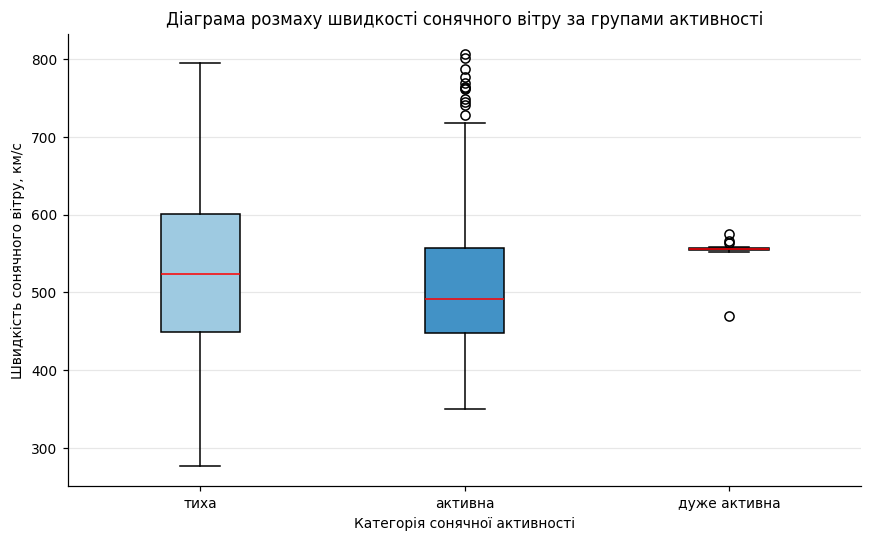

In [ ]:
# ВАШ КОД
groups = ["тиха", "активна", "дуже активна"]
data_by_group = [M[M["група"] == group]["SPEED"].dropna() for group in groups]

plt.figure(figsize=(8, 5))
bp = plt.boxplot(
    data_by_group, tick_labels=groups, patch_artist=True, medianprops={"color": "red"}
)

colors = ["#9ecae1", "#4292c6", "#084594"]
for patch, color in zip(bp["boxes"], colors):
    patch.set_facecolor(color)

plt.title("Діаграма розмаху швидкості сонячного вітру за групами активності")
plt.xlabel("Категорія сонячної активності")
plt.ylabel("Швидкість сонячного вітру, км/с")
plt.grid(True, axis="y", alpha=0.3)
plt.tight_layout()

plt.show()

**Висновок:**
Середня швидкість сонячного вітру в усіх групах тримається в межах 490–555 км/с. Проте підвищена сонячна активність чітко проявляється появою поодиноких екстремальних сплесків швидкості до 800+ км/с.

### Графік 3. Чи пов'язані змінні вашої пари?

Побудуйте діаграму розсіювання для пари з вашого завдання. Порахуйте коефіцієнт
кореляції між ними.

Коефіцієнт кореляції між швидкістю та P>10: 0.078



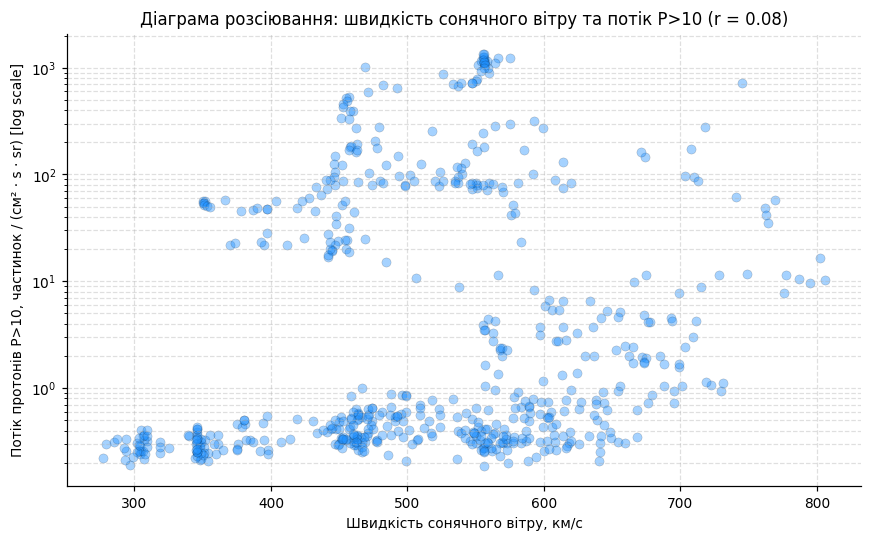

In [ ]:
# ВАШ КОД
col_speed = "SPEED"
col_p10 = "P>10_max" 

corr = M[col_speed].corr(M[col_p10])
print(f"Коефіцієнт кореляції між швидкістю та P>10: {corr:.3f}\n")

plt.figure(figsize=(8, 5))
plt.scatter(
    M[col_speed],
    M[col_p10],
    alpha=0.4,
    color="dodgerblue",
    edgecolors="k",
    linewidths=0.2,
)

plt.yscale("log")

plt.title(
    f"Діаграма розсіювання: швидкість сонячного вітру та потік P>10 (r = {corr:.2f})"
)
plt.xlabel("Швидкість сонячного вітру, км/с")
plt.ylabel("Потік протонів P>10, частинок / (см² · s · sr) [log scale]")
plt.grid(True, which="both", linestyle="--", alpha=0.4)
plt.tight_layout()

plt.show()

**Висновок:**
Значення коефіцієнта кореляції r = 0.078 свідчить про практичну відсутність лінійного зв'язку між швидкістю сонячного вітру та потоком протонів P>10.

### Графік 4. Скільки годин у кожній групі?

Побудуйте стовпчикову діаграму кількості годин за групами. Підпишіть кожен стовпчик
кількістю годин і відсотком від загальної кількості.

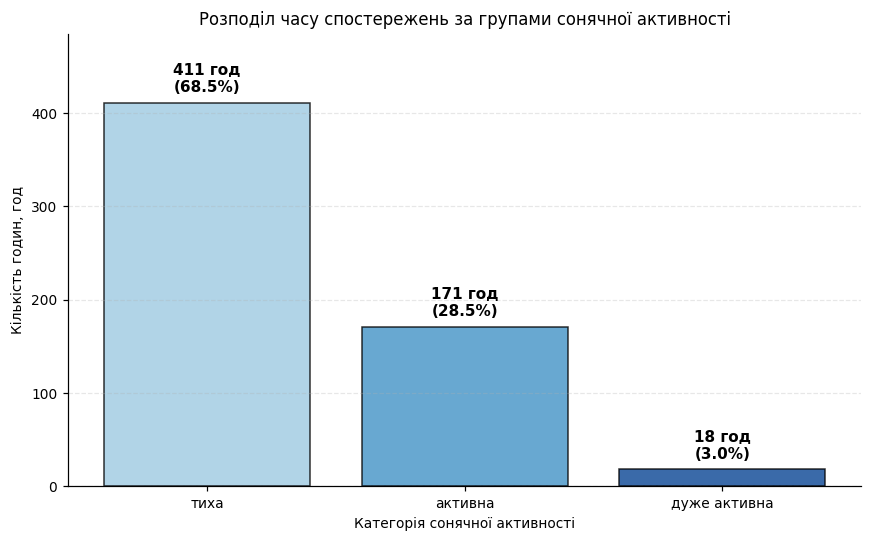

In [ ]:
# ВАШ КОД
groups = ["тиха", "активна", "дуже активна"]
counts = M["група"].value_counts().reindex(groups, fill_value=0)
total_hours = counts.sum()

plt.figure(figsize=(8, 5))
bars = plt.bar(
    counts.index,
    counts.values,
    color=["#9ecae1", "#4292c6", "#084594"],
    edgecolor="black",
    alpha=0.8,
)

for bar in bars:
    height = bar.get_height()
    pct = (height / total_hours) * 100 if total_hours > 0 else 0
    plt.text(
        bar.get_x() + bar.get_width() / 2.0,
        height + (max(counts.values) * 0.02),
        f"{int(height)} год\n({pct:.1f}%)",
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold",
    )

plt.title("Розподіл часу спостережень за групами сонячної активності")
plt.xlabel("Категорія сонячної активності")
plt.ylabel("Кількість годин, год")
plt.ylim(0, max(counts.values) * 1.18)  
plt.grid(True, axis="y", linestyle="--", alpha=0.3)
plt.tight_layout()

plt.show()

**Висновок:**
Переважну більшість часу (68.5%) середовище перебуває у «тихому» стані, тоді як помірно активні періоди займають 28.5%, а екстремальний рівень активності становить лише 3.0% часу.

### Графік 5. Як усе це виглядало в часі?

Побудуйте лінійний графік максимуму потоку P>10 за годину за весь період спостережень.

Якщо крива виявиться нечитабельною — згадайте, що допомогло в графіку 1.

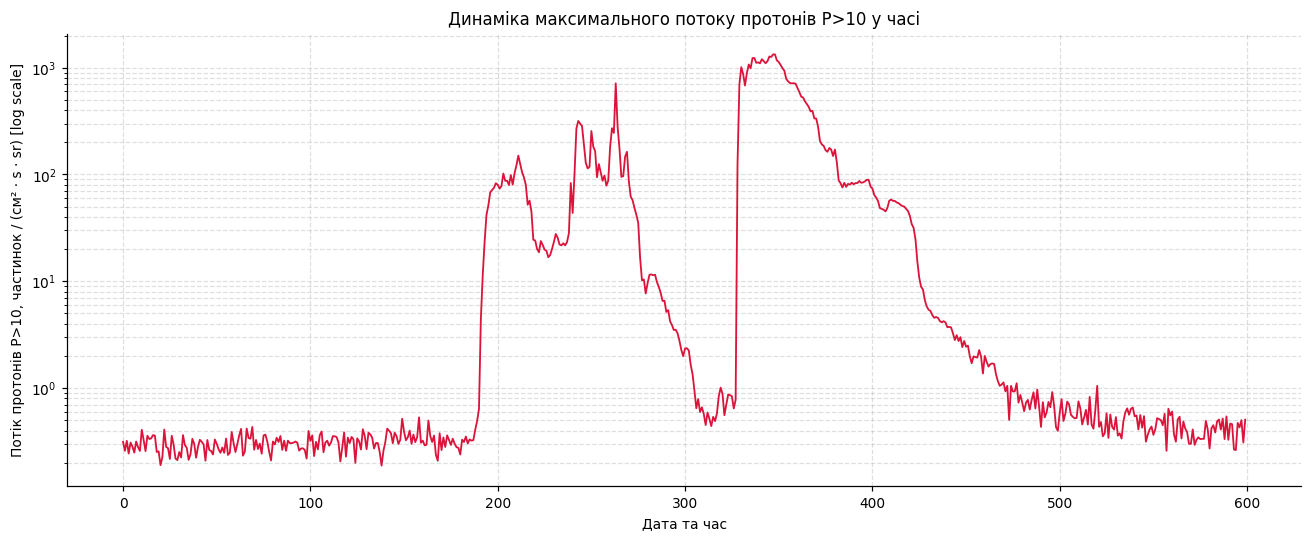

In [ ]:
# ВАШ КОД

col_p10 = "P>10_max"


plt.figure(figsize=(12, 5))
plt.plot(M.index, M[col_p10], color="crimson", linewidth=1.2)

plt.yscale("log")

plt.title("Динаміка максимального потоку протонів P>10 у часі")
plt.xlabel("Дата та час")
plt.ylabel("Потік протонів P>10, частинок / (см² · s · sr) [log scale]")
plt.grid(True, which="both", linestyle="--", alpha=0.4)
plt.tight_layout()

plt.show()

**Висновок:**
Більшість часу потік протонів залишається дуже низьким (менше 1), але на графіку чітко видно два потужні спалахи, коли рівень радіації зростав у понад 1000 разів.

---

# Етап 6. Два графіки одних і тих самих даних

Нижче побудовано два графіки. Дані в них **одні й ті самі** — це той самий стовпець
з тієї самої таблиці, жодне число не змінено.

Виконайте клітинку й подивіться на обидва.

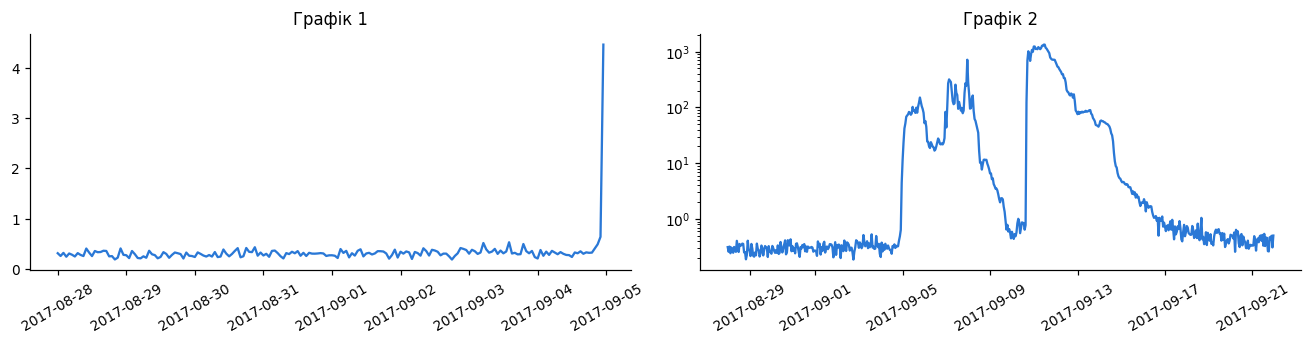

In [ ]:
СТОВПЕЦЬ = 'P>10_max'   # <- впишіть назву свого стовпця з МАКСИМУМОМ P>10 за годину

вікно = M[(M['ts'] >= '2017-08-28') & (M['ts'] < '2017-09-05')]

fig, ax = plt.subplots(1, 2, figsize=(12, 3.2))

ax[0].plot(вікно['ts'], вікно[СТОВПЕЦЬ], color='#2a78d6')
ax[0].set_title('Графік 1')
ax[0].tick_params(axis='x', rotation=30)

ax[1].plot(M['ts'], M[СТОВПЕЦЬ], color='#2a78d6')
ax[1].set_yscale('log')
ax[1].set_title('Графік 2')
ax[1].tick_params(axis='x', rotation=30)

fig.tight_layout()

plt.show()

### Завдання 6.1

Дайте відповідь на три питання:

1. Який висновок про космічну погоду у вересні 2017 року зробить людина, яка бачила
**тільки перший** графік?
2. Який висновок зробить людина, яка бачила **тільки другий**?
3. Чим ці два графіки відрізняються між собою? Назвіть **дві** відмінності —
вони обидві є в коді вище.

*Жодне число в обох графіках не підроблене. Різниця виникла тільки через те,
як їх побудували.*

**Відповідь 6.1:**

1. Висновок з першого графіка: Космічна погода наприкінці серпня та на початку вересня була спокійною, і лише 4–5 вересня починається якесь незначне зростання. Людина вирішить, що це була коротка та слабка локальна подія, адже основна частина геомагнітного шторму залишилася за межами графіка.
2. Висновок з другого графіка: У вересні 2017 року відбулися дві потужні екстремальні сонячні радіаційні бурі (із піком понад 10^3 близько 10 вересня), після яких протонне середовище відновлювалося до нормального стану понад тиждень.
3. Дві відмінності між ними: Часовий діапазон (обсяг даних): Перший графік показує лише вузьке часове вікно з 28 серпня по 5 вересня (вікно), тоді як другий графік охоплює весь період спостережень у вересні (M). Масштаб осі Y: Перший графік побудований у лінійному масштабі (за замовчуванням), а для другого застосовано логарифмічну шкалу (ax[1].set_yscale('log')).

### Завдання 6.2

Уявіть, що вам потрібно **одним графіком** чесно показати, що відбувалося в цьому
періоді. Побудуйте його самі й підпишіть заголовком, який формулює висновок.

Поясніть у клітинці нижче, чому ви обрали саме такий вигляд.

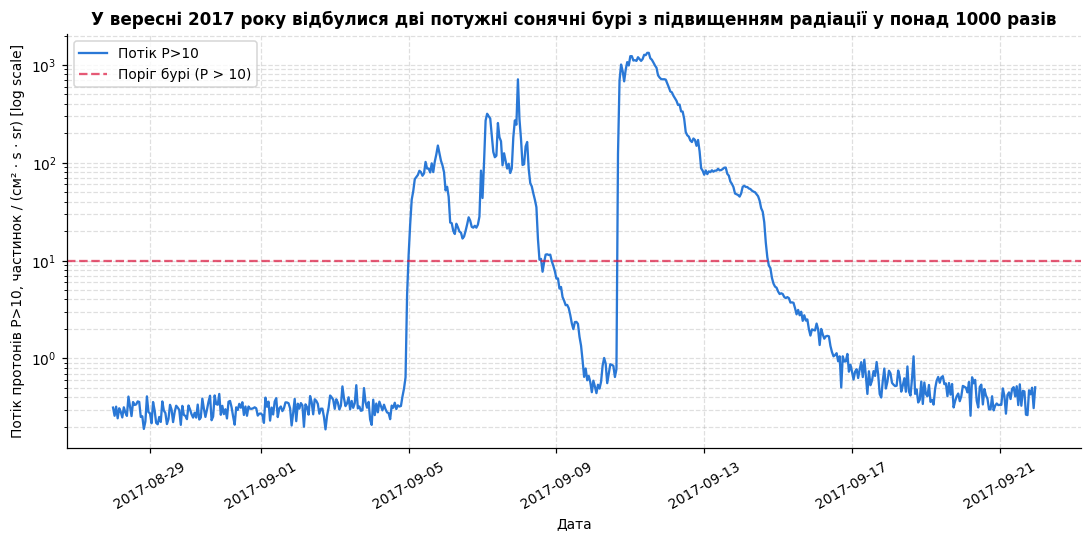

In [ ]:
# ВАШ КОД
СТОВПЕЦЬ = "P>10_max" 

plt.figure(figsize=(10, 5))
plt.plot(M["ts"], M[СТОВПЕЦЬ], color="#2a78d6", linewidth=1.5, label="Потік P>10")

plt.yscale("log")

plt.axhline(
    y=10,
    color="crimson",
    linestyle="--",
    alpha=0.7,
    label="Поріг бурі (P > 10)",
)

plt.title(
    "У вересні 2017 року відбулися дві потужні сонячні бурі з підвищенням радіації у понад 1000 разів",
    fontsize=11,
    fontweight="bold",
)

plt.xlabel("Дата")
plt.ylabel("Потік протонів P>10, частинок / (см² · s · sr) [log scale]")
plt.xticks(rotation=30)
plt.grid(True, which="both", linestyle="--", alpha=0.4)
plt.legend(loc="upper left")
plt.tight_layout()

plt.show()

**Відповідь 6.2:** *(чому ви побудували графік саме так)*
Цей графік є найбільш об'єктивним, оскільки охоплює весь період спостережень та використовує логарифмічну шкалу, що дозволяє чесно й без викривлень показати як дрібні фонові коливання, так і справжній масштаб екстремальних сонячних бурь.

---

# Етап 7. Три спостереження та ваше питання

### Завдання 7.1

Запишіть **три спостереження** про ці дані, які ви зробили під час роботи.

Спостереження — це твердження, яке спирається на конкретне число або графік з вашого
ноутбука. Не «дані цікаві», а, наприклад, «максимальне значення потоку у 2000 разів
більше за медіанне, і всі такі години припадають на одні й ті самі три доби».

Для кожного вкажіть, **де саме** у вашій роботі його видно.

**Спостереження 1:**
За даними розподілу активності, 68.5% часу (411 годин) середовище перебуває у «тихому» стані, а екстремальна радіаційна небезпека займає лише 3.0% спостережень (18 годин).

**Спостереження 2:**
Попри відсутність лінійної кореляції між швидкістю сонячного вітру та потоком протонів, усі екстремальні радіаційні сплески (P>10 > 10^3) відбувалися виключно за високої швидкості вітру понад 500 км/с.
**Спостереження 3:**
Часові ряди показують, що протонні шторми виникають раптово за кілька годин, а процес їхнього згасання та повернення до безпечного фонового рівня є затяжним і триває понад 100 годин.

### Завдання 7.2 — ваше індивідуальне питання

Дайте відповідь на додаткове питання зі свого завдання. Відповідь має спиратися
на обчислення: наведіть код і результат, а потім сформулюйте висновок словами.

Результат обчислення:
- Година з максимальним середнім потоком: 19:00 UTC
- Максимальне середнє значення: 119225.66


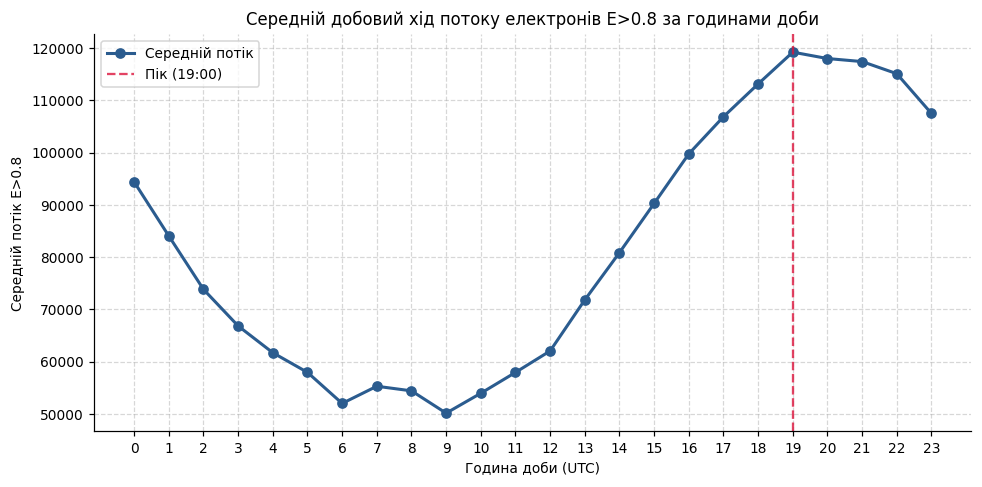

In [ ]:
# ВАШ КОД
col_e08 = [c for c in M.columns if "E>0.8" in c][0]

if "ts" in M.columns:
    M["hour"] = pd.to_datetime(M["ts"]).dt.hour
else:
    M["hour"] = M.index.hour

hourly_avg = M.groupby("hour")[col_e08].mean()

max_hour = int(hourly_avg.idxmax())
max_value = hourly_avg.max()

print(f"Результат обчислення:")
print(f"- Година з максимальним середнім потоком: {max_hour}:00 UTC")
print(f"- Максимальне середнє значення: {max_value:.2f}")

plt.figure(figsize=(9, 4.5))
plt.plot(
    hourly_avg.index,
    hourly_avg.values,
    marker="o",
    color="#2b5c8f",
    linewidth=2,
    label="Середній потік",
)
plt.axvline(
    x=max_hour,
    color="crimson",
    linestyle="--",
    alpha=0.8,
    label=f"Пік ({max_hour}:00)",
)

plt.title("Середній добовий хід потоку електронів E>0.8 за годинами доби")
plt.xlabel("Година доби (UTC)")
plt.ylabel("Середній потік E>0.8")
plt.xticks(range(0, 24))
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend()
plt.tight_layout()

plt.show()

**Відповідь 7.2:**
Середній потік електронів E>0.8 досягає свого максимуму о 19:00 UTC зі значенням 119 225.66

---

# Етап 8. Декларація про використання інструментів штучного інтелекту

Користуватися мовними моделями під час виконання цієї роботи **дозволено**. Це
нормальна інженерна практика, і курс про штучний інтелект не має підстав її забороняти.

Обов'язковою є прозорість: ви вказуєте, де саме і як скористалися інструментом —
так само, як у науковій статті вказують використане програмне забезпечення.
**Задекларована допомога порушенням не є.**

Порушенням є інше: здати роботу, яку ви не можете пояснити. На захисті вас попросять
показати конкретний рядок вашого коду, пояснити, чому він саме такий, і внести в нього
невелику зміну на місці. Якщо код згенеровано, але ви його розумієте — робота
зарахована. Якщо не розумієте — не зарахована, незалежно від того, хто його написав.

### Завдання 8.1

Заповніть словник. Для кожного етапу оберіть одне з формулювань:

- `'ні'` — інструментами ШІ не користувався;
- `'синтаксис'` — питав про назву функції або синтаксис, код писав сам;
- `'код, перевірено'` — код згенеровано, я його прочитав, перевірив і розумію;
- `'текст, перероблено'` — згенеровано чернетку тексту, яку я переписав по суті;
- `'текст, як є'` — згенерований текст залишено майже без змін.

Останній варіант не заборонений, але прямо впливає на оцінку: бали ставляться
за висновки, а не за наявність абзацу.

In [28]:
ІНСТРУМЕНТИ_ШІ = 'Gemini'     # напр. 'ChatGPT' або 'не використовував'

ДЕКЛАРАЦІЯ = {
    'етапи 1–2, читання файлу та розбір таблиць': 'синтаксис',
    'етап 3, паспорт даних і дивні значення':     'синтаксис',
    'етап 4, об’єднання таблиць':                 'код, перевірено',
    'етап 5, побудова графіків':                  'синтаксис',
    'етап 5, формулювання висновків':             'текст, перероблено',
    'етапи 6–7, порівняння графіків і спостереження': 'текст, перероблено',
}

# Що саме ви перевірили за згенерованим кодом чи текстом — конкретно:
# які числа звірили, що переписали, де знайшли помилку.
ЩО_ПЕРЕВІРЕНО = "Синтаксис: перевірено коректність синтаксису pandas (групування за годинами groupby) та налаштування логарифмічної шкали в matplotlib. Висновки: переписано та спрощено згенеровані підписи й підсумки, зробивши їх короткими та точними"

# True означає: я можу пояснити кожен рядок свого коду, відтворити будь-який
# результат цієї роботи та внести зміни в код на вимогу під час захисту.
ПІДТВЕРДЖУЮ = True

In [29]:
# --- перевірка повноти декларації: клітинку не редагувати --------------------
ДОЗВОЛЕНІ = {'ні', 'синтаксис', 'код, перевірено', 'текст, перероблено', 'текст, як є'}

assert ІНСТРУМЕНТИ_ШІ.strip(), 'Вкажіть інструменти або напишіть «не використовував»'
порожні = [k for k, v in ДЕКЛАРАЦІЯ.items() if not str(v).strip()]
assert not порожні, 'Не заповнено пункти декларації: %s' % '; '.join(порожні)
чужі = {v for v in ДЕКЛАРАЦІЯ.values() if v not in ДОЗВОЛЕНІ}
assert not чужі, 'Недопустимі значення: %s. Оберіть з переліку вище.' % ', '.join(sorted(чужі))
assert len(ЩО_ПЕРЕВІРЕНО.strip()) >= 120, ('Опишіть конкретніше, що саме ви перевірили '
                                           '(зараз %d символів, потрібно щонайменше 120)'
                                           % len(ЩО_ПЕРЕВІРЕНО.strip()))
assert ПІДТВЕРДЖУЮ is True, 'Підтвердьте, що можете пояснити власний код на захисті'

print('ДЕКЛАРАЦІЯ ПРО ВИКОРИСТАННЯ ІНСТРУМЕНТІВ ШІ')
print('=' * 78)
print('%-46s %s' % ('автор:', ПІБ))
print('%-46s %s' % ('інструменти:', ІНСТРУМЕНТИ_ШІ))
print('-' * 78)
for k, v in ДЕКЛАРАЦІЯ.items():
    print('%-46s %s' % (k + ':', v))
print('-' * 78)
print('перевірено автором:')
print(ЩО_ПЕРЕВІРЕНО)
print('=' * 78)
print('Автор підтверджує, що може пояснити кожен рядок коду під час захисту.')

ДЕКЛАРАЦІЯ ПРО ВИКОРИСТАННЯ ІНСТРУМЕНТІВ ШІ
автор:                                         Ільящук Марта Тарасівна
інструменти:                                   Gemini
------------------------------------------------------------------------------
етапи 1–2, читання файлу та розбір таблиць:    синтаксис
етап 3, паспорт даних і дивні значення:        синтаксис
етап 4, об’єднання таблиць:                    код, перевірено
етап 5, побудова графіків:                     синтаксис
етап 5, формулювання висновків:                текст, перероблено
етапи 6–7, порівняння графіків і спостереження: текст, перероблено
------------------------------------------------------------------------------
перевірено автором:
Синтаксис: перевірено коректність синтаксису pandas (групування за годинами groupby) та налаштування логарифмічної шкали в matplotlib. Висновки: переписано та спрощено згенеровані підписи й підсумки, зробивши їх короткими та точними
Автор підтверджує, що може пояснити кожен рядок коду 

---

# Крок 9. Збереження результату та фінальна самоперевірка

Об'єднана таблиця знадобиться вам у лабораторних роботах № 3 і № 4 — збережіть її
й не втрачайте до кінця семестру.

In [30]:
M.to_csv('master_hourly.csv', index=False)
print('збережено:', M.shape)

збережено: (601, 29)


In [31]:
# --- фінальна самоперевірка --------------------------------------------------
перевірки = {
    'ПІБ і варіант заповнено':        bool(ПІБ) and bool(ВАРІАНТ),
    'таблиця A (7200 рядків)':        len(A) == 7200,
    'таблиця B (25 рядків)':          len(B) == 25,
    'таблиця C (601 рядок)':          len(C) == 601,
    'таблиці об’єднано':              M is not None and 590 <= len(M) <= 605,
    'стовпець «група» є':             'група' in M.columns,
    'усі дати у 2017 році':           int(pd.to_datetime(M['ts']).dt.year.min()) == 2017,
    'декларацію заповнено':           bool(ІНСТРУМЕНТИ_ШІ.strip()) and ПІДТВЕРДЖУЮ is True,
}
for k, v in перевірки.items():
    print(('OK   ' if v else 'НЕ ОК') + '  ' + k)

if all(перевірки.values()):
    print('\nТехнічна частина роботи виконана.')
    print('Тепер переконайтеся, що заповнені ВСІ клітинки з відповідями та висновками,')
    print('і виконайте Kernel → Restart & Run All перед здачею.')

OK     ПІБ і варіант заповнено
OK     таблиця A (7200 рядків)
OK     таблиця B (25 рядків)
OK     таблиця C (601 рядок)
OK     таблиці об’єднано
OK     стовпець «група» є
OK     усі дати у 2017 році
OK     декларацію заповнено

Технічна частина роботи виконана.
Тепер переконайтеся, що заповнені ВСІ клітинки з відповідями та висновками,
і виконайте Kernel → Restart & Run All перед здачею.
